# Assignment 3 - Sampling Distributions and Estimation

Group members: Sebastian Halas, ...

Table of contents
1. Part I - Sampling distributions and the CLT
2. Part II - Estimating mean sensor error
3. Part III - Estimating a false-rejection proportion
4. Part IV - AI-use and conclusion

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [ ]:
sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")

display(sensors.head())
display(access.head())

# Part I Sampling distributions and the CLT

Restoration time is exponential with mean = SD = 60 minutes. We use seed 2026 and 20,000 repetitions for each sample size.

In [8]:
mu = sigma = 60
reps = 20_000
sizes = [1, 5, 20, 80]
rng = np.random.default_rng(2026)

means = {}
for n in sizes:
    samples = rng.exponential(scale=mu, size=(reps, n))
    means[n] = samples.mean(axis=1)

rows = []
for n in sizes:
    rows.append({
        "n": n,
        "theoretical mean": mu,
        "simulated mean of means": means[n].mean(),
        "theoretical SE": sigma / np.sqrt(n),
        "empirical SD of means": means[n].std(ddof=1),
    })
pd.DataFrame(rows)

,n,theoretical mean,simulated mean of means,theoretical SE,empirical SD of means
0,1,60,60.327869,60.000000,60.199020
1,5,60,59.500194,26.832816,26.683556
2,20,60,59.936719,13.416408,13.352604
3,80,60,59.990481,6.708204,6.739603


**a. Table**

The mean of the sample means is close to 60 for every n, so the sample mean is centred at the population mean. The SD of the sample means matches the theoretical SE (σ/√n). When n gets 4 times bigger (5 to 20, 20 to 80), the SE is cut in half.

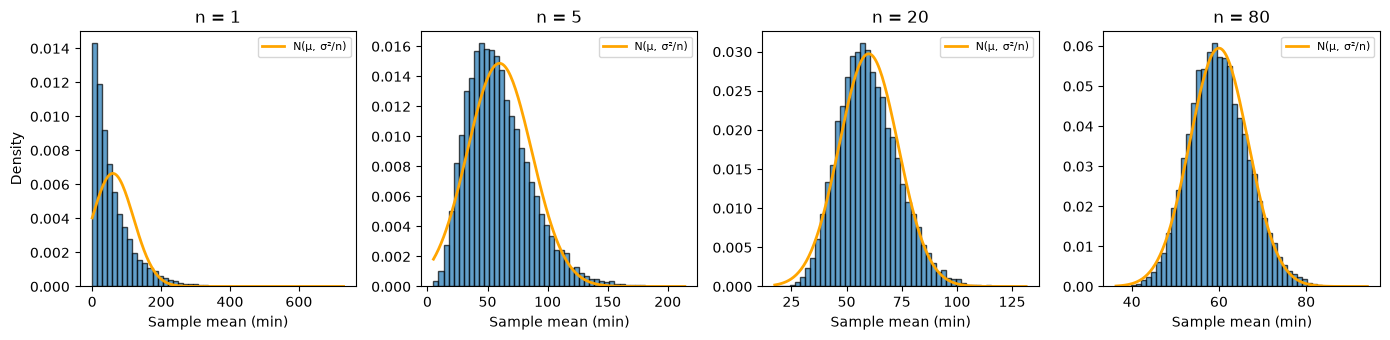

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, n in zip(axes, sizes):
    se = sigma / np.sqrt(n)
    ax.hist(means[n], bins=50, density=True, edgecolor="black", alpha=0.7)
    x = np.linspace(means[n].min(), means[n].max(), 200)
    ax.plot(x, norm.pdf(x, mu, se), color="orange", lw=2, label="N(μ, σ²/n)")
    ax.set(title=f"n = {n}", xlabel="Sample mean (min)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

**b. Sampling distributions**

- Centre: all four histograms are centred around 60.
- Spread: they get narrower as n grows, since the SE is σ/√n.
- Shape: for n = 1 it is just the exponential distribution, very skewed to the right, and the normal curve fits badly (it even goes below 0). For n = 5 it is still skewed, for n = 20 a bit less, and for n = 80 it looks almost normal.

The normal curve is only an approximation here because the population itself is not normal. If the population was normal, the sample mean would be exactly normal for any n. Here the CLT only says it gets closer to normal as n grows, but some skew is always left.

In [10]:
for n in [20, 80]:
    sim = np.mean(means[n] > 75)
    clt = norm.sf(75, loc=mu, scale=sigma / np.sqrt(n))
    print(f"n = {n}: simulated P(X̄ > 75) = {sim:.4f}, CLT approximation = {clt:.4f}")

n = 20: simulated P(X̄ > 75) = 0.1334, CLT approximation = 0.1318
n = 80: simulated P(X̄ > 75) = 0.0186, CLT approximation = 0.0127


**c. P(X̄ > 75)**

For n = 20 the simulation and the CLT give almost the same answer (0.133 vs 0.132). For n = 80 the simulation gives 0.019 and the CLT 0.013. The numbers are small, but the CLT is about 30% too low. 75 is far out in the right tail for n = 80, and the sample means are still a bit right-skewed, so the real tail is heavier than the normal curve. The CLT works well in the middle, but in the far tails it is less accurate.

**d. Smallest n with SE ≤ 6**

60/√n ≤ 6, so √n ≥ 10, so n ≥ 100.

In [11]:
n_min = int(np.ceil((sigma / 6) ** 2))
print(f"Smallest n: {n_min}")

for n in [n_min - 1, n_min]:
    sim_means = rng.exponential(scale=mu, size=(reps, n)).mean(axis=1)
    print(f"n = {n}: theoretical SE = {sigma / np.sqrt(n):.3f}, simulated SD of means = {sim_means.std(ddof=1):.3f}")

Smallest n: 100
n = 99: theoretical SE = 6.030, simulated SD of means = 6.080
n = 100: theoretical SE = 6.000, simulated SD of means = 6.019


So n = 100 is the smallest sample size (SE is exactly 6). With n = 99 the SE is just over 6. The simulated values are close to the theoretical ones, the small differences are just random noise.

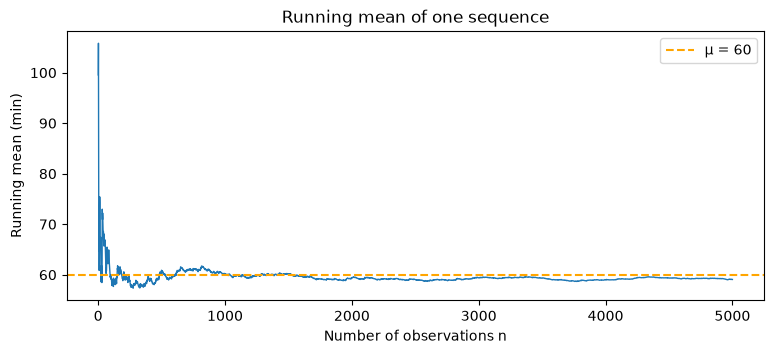

In [12]:
n_lln = 5_000
sequence = rng.exponential(scale=mu, size=n_lln)
running_mean = np.cumsum(sequence) / np.arange(1, n_lln + 1)

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, n_lln + 1), running_mean, lw=1)
plt.axhline(mu, color="orange", linestyle="--", label="μ = 60")
plt.xlabel("Number of observations n")
plt.ylabel("Running mean (min)")
plt.title("Running mean of one sequence")
plt.legend()
plt.show()

**e. Law of large numbers**

The running mean jumps around a lot at the start and then settles close to 60 as more observations are added. That is the law of large numbers: the more observations in one sample, the closer the sample mean gets to the population mean.

This is not a sampling distribution. Here we follow one sample that keeps growing. A sampling distribution uses many separate samples of the same size n and shows how much the mean varies between them. The LLN only says the mean gets close to 60, it does not say anything about the shape. The shape is what the CLT is about.

**f. What the CLT does not do**

The CLT is only about sample means. It does not make single restoration times normal, one restoration time is still exponential and skewed. It also assumes independent observations from the same population, so it does not help if:
- observations depend on each other (e.g. several outages from the same incident)
- the times change over time (e.g. slower repairs in a busy period)
- the sample is not representative (e.g. only daytime repairs)

# Part II Estimating mean sensor error

# Part III Estimating a false-rejection proportion

# Part IV AI-use and conclusion